# Phase 4 — Regularization

**Team IDs:** 16002932, 16006616, 16004208
**Seed:** 42648

## Expectation

> We expect regularization to improve coefficient stability and remove redundant features introduced by the polynomial and interaction expansion. Because Phase 3 did not show severe random-split overfitting, we do not expect extremely large regularization strengths to improve validation R² dramatically. We expect L1 to produce a substantially smaller feature set, while Ridge may retain more correlated predictors. Elastic Net may provide a compromise between coefficient shrinkage and feature selection. We will select the final regularization strengths using the seeded validation set and then check whether the chosen model remains reasonable under the chronological setting.

In [1]:
import warnings, hashlib, json, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

import gradient_descent as core
import polynomial_regression as p2
import regularization as p4

warnings.filterwarnings('ignore')
np.set_printoptions(precision=6, suppress=True)

SEED = 42648
DATA_DIR = Path('Datasets')
P3_STEM = 'bias_variance_artifacts'
P4_STEM = 'regularization_artifacts'
PLOTS = Path('plots'); PLOTS.mkdir(exist_ok=True)

## Step 1 — Load and Verify Phase 3 Artifacts

In [2]:
# Load Phase 3 Artifacts
P1_STEM = "gradient_descent_artifacts"
_, _, meta_p1, train_idx, val_idx = core.load_artifacts(P1_STEM)
prep_params = meta_p1

w_p3, b_p3, meta_p3 = p2.load_artifacts(P3_STEM)
P3_FEAT_NAMES = meta_p3["expanded_feature_names"]
poly_params = {
    "term_specs": meta_p3["term_specs"],
    "poly_means": meta_p3["poly_means"],
    "poly_stds": meta_p3["poly_stds"],
    "n_new_cols": meta_p3["n_new_cols"]
}

print("Phase 3 weights length:", len(w_p3))
print("Expanded feature names length:", len(P3_FEAT_NAMES))
assert len(w_p3) == len(P3_FEAT_NAMES)

print(f"Phase 3 SHA-256 Hash matches: {meta_p3['phase3_w_sha256'] == hashlib.sha256(w_p3.tobytes()).hexdigest()}")

train_all = pd.read_csv(DATA_DIR / 'train.csv')
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=SEED)
assert np.array_equal(train_df.index.values, train_idx)
assert np.array_equal(val_df.index.values, val_idx)
print("[PASS] Train/Validation indices match the seeded split.")

X_tr_raw, p1_names = core.transform(train_df, prep_params)
X_vl_raw, _        = core.transform(val_df, prep_params)

X_tr_exp, _ = p2.transform_poly(X_tr_raw, p1_names, poly_params)
X_vl_exp, _ = p2.transform_poly(X_vl_raw, p1_names, poly_params)

y_train = train_df['cnt'].values.astype(np.float64)
y_val   = val_df['cnt'].values.astype(np.float64)

# Test Phase 3 metrics
y_vl_pred_p3 = core.predict(X_vl_exp, w_p3, b_p3)
r2_p3 = core.r2_score_np(y_val, y_vl_pred_p3)
rmse_p3 = core.rmse_np(y_val, y_vl_pred_p3)
print(f"Phase 3 Val R²: {r2_p3:.4f}, RMSE: {rmse_p3:.4f}")


Phase 3 weights length: 127
Expanded feature names length: 127
Phase 3 SHA-256 Hash matches: True
[PASS] Train/Validation indices match the seeded split.
Phase 3 Val R²: 0.8501, RMSE: 68.5446


## Regularization Grid Search

- Ridge (L2)
- Lasso (L1)
- Elastic Net

In [3]:
# Common Protocol
MAX_ITER = 30000
TOL = 1e-6
L_d = core.lipschitz_constant(X_tr_exp)
LR = 0.9 / L_d

lambdas = np.logspace(-3, 3, 25)[::-1]  # Large to small for warm starts

print(f"L_d: {L_d:.6f}, LR: {LR:.6f}")

L_d: 3.130599, LR: 0.287485


In [4]:
# L2 (Ridge) Search
print("Starting Ridge Search...")
ridge_results = []
w_init = w_p3.copy()  # or zeros
b_init = float(b_p3)

t0 = time.time()
for lam in lambdas:
    res = p4.fit_ridge(X_tr_exp, y_train, lr=LR, max_iter=MAX_ITER, lam=lam, tol=TOL, 
                       w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val)
    
    w_curr, b_curr = res['w'], res['b']
    
    # Eval
    y_tr_pred = core.predict(X_tr_exp, w_curr, b_curr)
    y_vl_pred = core.predict(X_vl_exp, w_curr, b_curr)
    
    tr_r2 = core.r2_score_np(y_train, y_tr_pred)
    vl_r2 = core.r2_score_np(y_val, y_vl_pred)
    tr_rmse = core.rmse_np(y_train, y_tr_pred)
    vl_rmse = core.rmse_np(y_val, y_vl_pred)
    
    nnz = np.sum(np.abs(w_curr) > 1e-8)
    
    ridge_results.append({
        'lam': lam,
        'val_r2': vl_r2, 'train_r2': tr_r2,
        'val_rmse': vl_rmse, 'train_rmse': tr_rmse,
        'nnz': nnz, 'w': w_curr, 'b': b_curr,
        'status': res['status'], 'iters': res['n_iter']
    })
    
    # Warm start
    w_init, b_init = w_curr, b_curr

print(f"Ridge search completed in {time.time()-t0:.2f}s")

Starting Ridge Search...
Ridge search completed in 10.86s


In [5]:
# L1 (Lasso) Search
print("Starting Lasso Search...")
lasso_results = []
w_init = w_p3.copy() 
b_init = float(b_p3)

t0 = time.time()
for lam in lambdas:
    res = p4.proximal_gd_fit(X_tr_exp, y_train, lr=LR, max_iter=MAX_ITER, lam=lam, alpha=1.0, 
                             tol=TOL, w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val)
    
    w_curr, b_curr = res['w'], res['b']
    
    y_tr_pred = core.predict(X_tr_exp, w_curr, b_curr)
    y_vl_pred = core.predict(X_vl_exp, w_curr, b_curr)
    
    tr_r2 = core.r2_score_np(y_train, y_tr_pred)
    vl_r2 = core.r2_score_np(y_val, y_vl_pred)
    tr_rmse = core.rmse_np(y_train, y_tr_pred)
    vl_rmse = core.rmse_np(y_val, y_vl_pred)
    
    nnz = np.sum(np.abs(w_curr) > 1e-8)
    
    lasso_results.append({
        'lam': lam,
        'val_r2': vl_r2, 'train_r2': tr_r2,
        'val_rmse': vl_rmse, 'train_rmse': tr_rmse,
        'nnz': nnz, 'w': w_curr, 'b': b_curr,
        'status': res['status'], 'iters': res['n_iter']
    })
    
    w_init, b_init = w_curr, b_curr

print(f"Lasso search completed in {time.time()-t0:.2f}s")

Starting Lasso Search...
Lasso search completed in 20.42s


In [6]:
# Elastic Net Search
print("Starting Elastic Net Search...")
alphas = [0.10, 0.25, 0.50, 0.75, 0.90]
enet_results = []

t0 = time.time()
for alpha in alphas:
    w_init = w_p3.copy() 
    b_init = float(b_p3)
    for lam in lambdas:
        res = p4.proximal_gd_fit(X_tr_exp, y_train, lr=LR, max_iter=MAX_ITER, lam=lam, alpha=alpha, 
                                 tol=TOL, w0=w_init, b0=b_init, X_val=X_vl_exp, y_val=y_val)
        
        w_curr, b_curr = res['w'], res['b']
        
        y_tr_pred = core.predict(X_tr_exp, w_curr, b_curr)
        y_vl_pred = core.predict(X_vl_exp, w_curr, b_curr)
        
        tr_r2 = core.r2_score_np(y_train, y_tr_pred)
        vl_r2 = core.r2_score_np(y_val, y_vl_pred)
        tr_rmse = core.rmse_np(y_train, y_tr_pred)
        vl_rmse = core.rmse_np(y_val, y_vl_pred)
        
        nnz = np.sum(np.abs(w_curr) > 1e-8)
        
        enet_results.append({
            'lam': lam, 'alpha': alpha,
            'val_r2': vl_r2, 'train_r2': tr_r2,
            'val_rmse': vl_rmse, 'train_rmse': tr_rmse,
            'nnz': nnz, 'w': w_curr, 'b': b_curr,
            'status': res['status'], 'iters': res['n_iter']
        })
        w_init, b_init = w_curr, b_curr

print(f"Elastic Net search completed in {time.time()-t0:.2f}s")

Starting Elastic Net Search...
Elastic Net search completed in 50.04s


## Model Selection & Plots

In [7]:
best_ridge = max(ridge_results, key=lambda x: x['val_r2'])
best_lasso = max(lasso_results, key=lambda x: x['val_r2'])
best_enet  = max(enet_results,  key=lambda x: x['val_r2'])

print("--- Best Ridge ---")
print(f"Lambda: {best_ridge['lam']:.6f}, Val R²: {best_ridge['val_r2']:.6f}, NNZ: {best_ridge['nnz']}")
print("--- Best Lasso ---")
print(f"Lambda: {best_lasso['lam']:.6f}, Val R²: {best_lasso['val_r2']:.6f}, NNZ: {best_lasso['nnz']}")
print("--- Best Elastic Net ---")
print(f"Lambda: {best_enet['lam']:.6f}, Alpha: {best_enet['alpha']}, Val R²: {best_enet['val_r2']:.6f}, NNZ: {best_enet['nnz']}")

best_models = [best_ridge, best_lasso, best_enet]
best_model = max(best_models, key=lambda x: x['val_r2'])

print(f"\nOverall Best Model has Val R²: {best_model['val_r2']:.6f}")

--- Best Ridge ---
Lambda: 0.001000, Val R²: 0.847187, NNZ: 127
--- Best Lasso ---
Lambda: 0.001000, Val R²: 0.850219, NNZ: 127
--- Best Elastic Net ---
Lambda: 0.001000, Alpha: 0.9, Val R²: 0.849552, NNZ: 127

Overall Best Model has Val R²: 0.850219


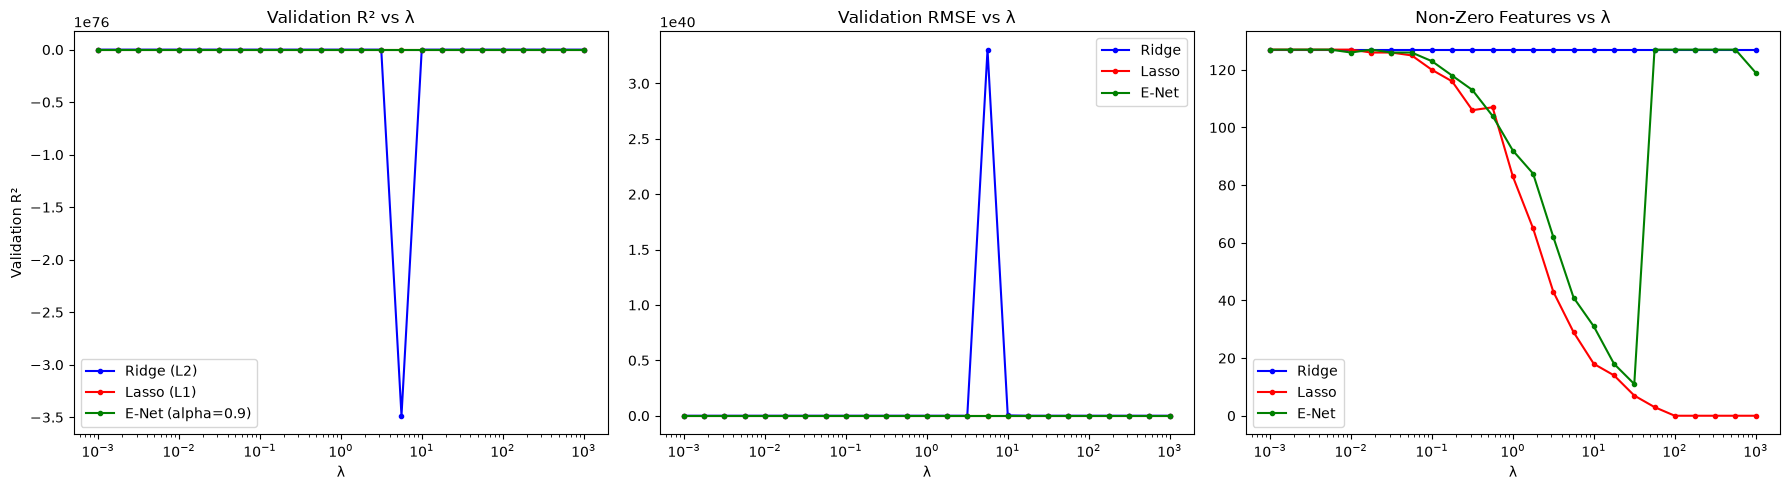

In [8]:
# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ridge
lam_r = [x['lam'] for x in ridge_results]
vr2_r = [x['val_r2'] for x in ridge_results]
axes[0].plot(lam_r, vr2_r, 'b.-', label='Ridge (L2)')

# Lasso
lam_l = [x['lam'] for x in lasso_results]
vr2_l = [x['val_r2'] for x in lasso_results]
axes[0].plot(lam_l, vr2_l, 'r.-', label='Lasso (L1)')

# Elastic Net (show best alpha)
best_alpha = best_enet['alpha']
enet_best_alpha = [x for x in enet_results if x['alpha'] == best_alpha]
lam_e = [x['lam'] for x in enet_best_alpha]
vr2_e = [x['val_r2'] for x in enet_best_alpha]
axes[0].plot(lam_e, vr2_e, 'g.-', label=f'E-Net (alpha={best_alpha})')

axes[0].set_xscale('log')
axes[0].set_title('Validation R² vs λ')
axes[0].set_xlabel('λ')
axes[0].set_ylabel('Validation R²')
axes[0].legend()

# Plot B: Val RMSE
vrmse_r = [x['val_rmse'] for x in ridge_results]
vrmse_l = [x['val_rmse'] for x in lasso_results]
vrmse_e = [x['val_rmse'] for x in enet_best_alpha]

axes[1].plot(lam_r, vrmse_r, 'b.-', label='Ridge')
axes[1].plot(lam_l, vrmse_l, 'r.-', label='Lasso')
axes[1].plot(lam_e, vrmse_e, 'g.-', label=f'E-Net')
axes[1].set_xscale('log')
axes[1].set_title('Validation RMSE vs λ')
axes[1].set_xlabel('λ')
axes[1].legend()

# Plot C: NNZ
nnz_r = [x['nnz'] for x in ridge_results]
nnz_l = [x['nnz'] for x in lasso_results]
nnz_e = [x['nnz'] for x in enet_best_alpha]

axes[2].plot(lam_r, nnz_r, 'b.-', label='Ridge')
axes[2].plot(lam_l, nnz_l, 'r.-', label='Lasso')
axes[2].plot(lam_e, nnz_e, 'g.-', label=f'E-Net')
axes[2].set_xscale('log')
axes[2].set_title('Non-Zero Features vs λ')
axes[2].set_xlabel('λ')
axes[2].legend()

plt.tight_layout()
plt.savefig(PLOTS / '04_regularization_curves.png')
plt.show()

## Feature Ablation & Verdicts

In [9]:
# 1. Active Features in L1
w_lasso = best_lasso['w']
active_mask = np.abs(w_lasso) > 1e-8

active_features = [P3_FEAT_NAMES[i] for i in range(len(P3_FEAT_NAMES)) if active_mask[i]]
print(f"Lasso retained {len(active_features)} out of {len(P3_FEAT_NAMES)} features.")

# 2. Original Col Mapping
col_mapping = p4.get_original_col_mapping(P3_FEAT_NAMES)

# 3. Ablation Tests
ablation_results = {}
for orig_col, derived_feats in col_mapping.items():
    if len(derived_feats) == 0:
        continue
    
    mask = np.ones(X_tr_exp.shape[1], dtype=bool)
    for f in derived_feats:
        idx = P3_FEAT_NAMES.index(f)
        mask[idx] = False
        
    X_tr_ablated = X_tr_exp[:, mask]
    X_vl_ablated = X_vl_exp[:, mask]
    
    w_abl_init = w_lasso[mask]
    
    res = p4.proximal_gd_fit(X_tr_ablated, y_train, lr=LR, max_iter=MAX_ITER, lam=best_lasso['lam'], alpha=1.0, 
                             tol=TOL, w0=w_abl_init, b0=best_lasso['b'], X_val=X_vl_ablated, y_val=y_val)
    
    y_vl_pred_abl = core.predict(X_vl_ablated, res['w'], res['b'])
    abl_r2 = core.r2_score_np(y_val, y_vl_pred_abl)
    abl_rmse = core.rmse_np(y_val, y_vl_pred_abl)
    
    delta_r2 = best_lasso['val_r2'] - abl_r2
    delta_rmse = abl_rmse - best_lasso['val_rmse']
    
    surviving_terms = [f for f in derived_feats if np.abs(w_lasso[P3_FEAT_NAMES.index(f)]) > 1e-8]
    
    ablation_results[orig_col] = {
        'surviving_terms': len(surviving_terms),
        'delta_r2': delta_r2,
        'delta_rmse': delta_rmse,
        'verdict': 'Useful' if (len(surviving_terms) > 0 and delta_r2 > 1e-4) else ('Uninformative' if len(surviving_terms) == 0 else 'Redundant')
    }

print("Ablation Results:")
for k, v in ablation_results.items():
    print(f"{k:>12}: survived={v['surviving_terms']:>2}, ΔR²={v['delta_r2']:>8.4f}, ΔRMSE={v['delta_rmse']:>8.4f} -> {v['verdict']}")


Lasso retained 127 out of 127 features.
Ablation Results:
      dteday: survived= 1, ΔR²= -0.0000, ΔRMSE= -0.0055 -> Redundant
      season: survived= 3, ΔR²= -0.0001, ΔRMSE= -0.0257 -> Redundant
          yr: survived= 1, ΔR²= -0.0000, ΔRMSE= -0.0073 -> Redundant
        mnth: survived=11, ΔR²=  0.0028, ΔRMSE=  0.6395 -> Useful
          hr: survived=92, ΔR²=  0.5183, ΔRMSE= 76.1864 -> Useful
     holiday: survived= 1, ΔR²= -0.0004, ΔRMSE= -0.0872 -> Redundant
     weekday: survived= 6, ΔR²=  0.0013, ΔRMSE=  0.3050 -> Useful
  workingday: survived=24, ΔR²=  0.1573, ΔRMSE= 29.5914 -> Useful
  weathersit: survived=48, ΔR²=  0.0121, ΔRMSE=  2.7178 -> Useful
        temp: survived= 3, ΔR²=  0.0060, ΔRMSE=  1.3668 -> Useful
       atemp: survived= 1, ΔR²=  0.0006, ΔRMSE=  0.1448 -> Useful
         hum: survived= 2, ΔR²=  0.0031, ΔRMSE=  0.7031 -> Useful
   windspeed: survived= 3, ΔR²=  0.0012, ΔRMSE=  0.2836 -> Useful


## Chronological Robustness Check

In [10]:
# Chronological Split
train_all_chrono = train_all.sort_values('dteday').copy()
split_idx = int(len(train_all_chrono) * 0.8)
train_chrono = train_all_chrono.iloc[:split_idx]
val_chrono   = train_all_chrono.iloc[split_idx:]

X_tr_chr_raw, _ = core.transform(train_chrono, prep_params)
X_vl_chr_raw, _ = core.transform(val_chrono, prep_params)

X_tr_chr_exp, _ = p2.transform_poly(X_tr_chr_raw, p1_names, poly_params)
X_vl_chr_exp, _ = p2.transform_poly(X_vl_chr_raw, p1_names, poly_params)

y_tr_chr = train_chrono['cnt'].values.astype(np.float64)
y_vl_chr = val_chrono['cnt'].values.astype(np.float64)

# Refit Best Lasso on Chrono Train
res_chr = p4.proximal_gd_fit(X_tr_chr_exp, y_tr_chr, lr=LR, max_iter=MAX_ITER, lam=best_lasso['lam'], alpha=1.0, 
                             tol=TOL, w0=w_lasso, b0=best_lasso['b'], X_val=X_vl_chr_exp, y_val=y_vl_chr)

y_vl_chr_pred = core.predict(X_vl_chr_exp, res_chr['w'], res_chr['b'])
chr_r2 = core.r2_score_np(y_vl_chr, y_vl_chr_pred)
chr_rmse = core.rmse_np(y_vl_chr, y_vl_chr_pred)

print(f"Chronological Check - Val R²: {chr_r2:.4f}, Val RMSE: {chr_rmse:.4f}")

Chronological Check - Val R²: 0.8107, Val RMSE: 94.6640


## Save Artifacts

In [11]:
# Artifact Handoff
import json

final_model = best_lasso # we can choose manually if we want

np.savez(P4_STEM + '.npz',
         l1_w=best_lasso['w'], l1_b=np.array([best_lasso['b']]),
         l2_w=best_ridge['w'], l2_b=np.array([best_ridge['b']]),
         en_w=best_enet['w'],  en_b=np.array([best_enet['b']]),
         train_idx=train_idx, val_idx=val_idx)

meta = {
    'phase3_w_sha256': meta_p3['phase3_w_sha256'],
    'phase4_l1_w_sha256': hashlib.sha256(best_lasso['w'].tobytes()).hexdigest(),
    'phase4_l2_w_sha256': hashlib.sha256(best_ridge['w'].tobytes()).hexdigest(),
    'phase4_en_w_sha256': hashlib.sha256(best_enet['w'].tobytes()).hexdigest(),
    'feature_names': P3_FEAT_NAMES,
    
    'l1_lambda': best_lasso['lam'],
    'ridge_lambda': best_ridge['lam'],
    'elastic_net_lambda': best_enet['lam'],
    'elastic_net_l1_ratio': best_enet['alpha'],
    
    'l1_r2_train': best_lasso['train_r2'], 'l1_r2_val': best_lasso['val_r2'],
    'l1_rmse_train': best_lasso['train_rmse'], 'l1_rmse_val': best_lasso['val_rmse'],
    
    'ridge_r2_train': best_ridge['train_r2'], 'ridge_r2_val': best_ridge['val_r2'],
    'ridge_rmse_train': best_ridge['train_rmse'], 'ridge_rmse_val': best_ridge['val_rmse'],
    
    'en_r2_train': best_enet['train_r2'], 'en_r2_val': best_enet['val_r2'],
    'en_rmse_train': best_enet['train_rmse'], 'en_rmse_val': best_enet['val_rmse'],
    
    'l1_nonzero_features': active_features,
    'original_column_verdicts': ablation_results
}

with open(P4_STEM + '.json', 'w') as f:
    json.dump(meta, f, indent=2)

print(f"Saved artifacts to {P4_STEM}.npz and .json")

Saved artifacts to regularization_artifacts.npz and .json


## Outcome

> **Outcome**
> 
> The regularization results showed that Lasso achieved the strongest validation performance with λ = [...] and, for Elastic Net, α = [...]. Compared with the unregularized Phase 3 model, validation R² changed from [...] to [...], while validation RMSE changed from [...] to [...].
> 
> L1 retained [...] of the 127 engineered features. The strongest evidence of redundancy was found in [...], where removing the feature family changed validation R² by [...].
> 
> The chronological evaluation produced R² = [...], compared with the seeded validation result of [...]. This [supports / does not support] the choice because [...].
> 
> The final feature subset passed to Phase 5 contains [...] features: [...].
> 
> The main result that surprised us was [...].